In [1]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, confusion_matrix
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

# Load data and display the first 5 images

Dataset shape: (1797, 64)
Number of classes: 10


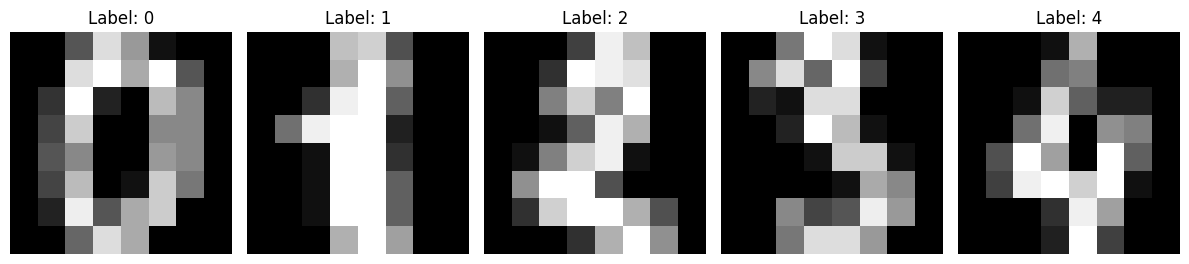

In [2]:
digits = load_digits()

X = digits.data
y = digits.target

print("Dataset shape:", X.shape)
print("Number of classes:", len(np.unique(y)))

fig, axes = plt.subplots(1, 5, figsize=(12, 3))

for i, ax in enumerate(axes):
    ax.imshow(digits.images[i], cmap="gray")
    ax.set_title(f"Label: {y[i]}")
    ax.axis("off")

plt.tight_layout()
plt.show()

# Split data 80/20 (stratified)

In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# KNN with k=5

In [4]:
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train, y_train)

y_pred = knn.predict(X_test)

print("Test accuracy:", accuracy_score(y_test, y_pred))

cm = confusion_matrix(y_test, y_pred)
print("Confusion matrix:\n", cm)

# Find the two different digits most often confused
cm_off = cm.copy()
np.fill_diagonal(cm_off, 0)

i, j = np.unravel_index(np.argmax(cm_off), cm_off.shape)

print(f"Most common confusion: actual {i} predicted as {j}")
print("Count:", cm_off[i, j])


c) KNN with k=5
Test accuracy: 0.9833333333333333
Confusion matrix:
 [[36  0  0  0  0  0  0  0  0  0]
 [ 0 36  0  0  0  0  0  0  0  0]
 [ 0  0 35  0  0  0  0  0  0  0]
 [ 0  0  0 37  0  0  0  0  0  0]
 [ 0  0  0  0 36  0  0  0  0  0]
 [ 0  0  0  0  0 37  0  0  0  0]
 [ 0  0  0  0  0  0 35  0  1  0]
 [ 0  0  0  0  0  0  0 36  0  0]
 [ 0  2  0  0  0  0  0  1 32  0]
 [ 0  0  0  0  1  0  0  0  1 34]]
Most common confusion: actual 8 predicted as 1
Count: 2


# 5-fold cross-validation for odd k values from 1 to 15


k=1, CV accuracy=0.9902
k=3, CV accuracy=0.9882
k=5, CV accuracy=0.9868
k=7, CV accuracy=0.9798
k=9, CV accuracy=0.9791
k=11, CV accuracy=0.9770
k=13, CV accuracy=0.9756
k=15, CV accuracy=0.9756


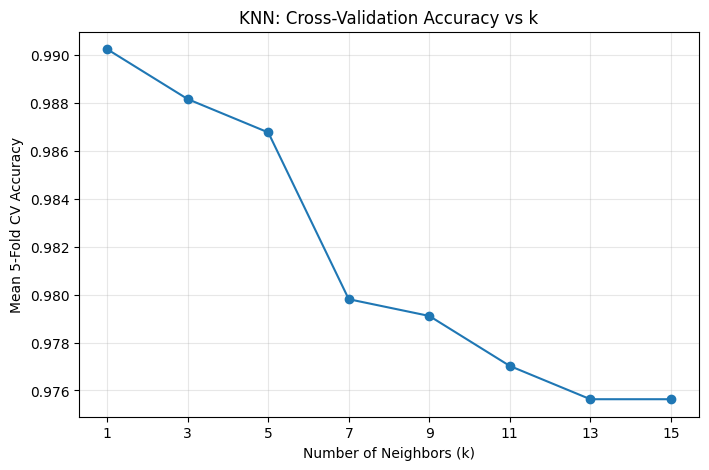

Best k: 1
Best CV accuracy: 0.9902463221060781


In [5]:
k_values = list(range(1, 16, 2))
cv_accuracies = []

for k in k_values:
    model = KNeighborsClassifier(n_neighbors=k)

    scores = cross_val_score(
        model,
        X_train,
        y_train,
        cv=5,
        scoring="accuracy"
    )

    cv_accuracies.append(scores.mean())
    print(f"k={k}, CV accuracy={scores.mean():.4f}")

plt.figure(figsize=(8, 5))
plt.plot(k_values, cv_accuracies, marker="o")
plt.xlabel("Number of Neighbors (k)")
plt.ylabel("Mean 5-Fold CV Accuracy")
plt.title("KNN: Cross-Validation Accuracy vs k")
plt.xticks(k_values)
plt.grid(True, alpha=0.3)
plt.show()

best_k = k_values[np.argmax(cv_accuracies)]
print("Best k:", best_k)
print("Best CV accuracy:", max(cv_accuracies))


# Compare Euclidean and Manhattan distances using best k


In [6]:
for metric in ["euclidean", "manhattan"]:
    model = KNeighborsClassifier(
        n_neighbors=best_k,
        metric=metric
    )

    model.fit(X_train, y_train)
    pred = model.predict(X_test)

    print(f"\nMetric: {metric}")
    print("Test accuracy:", accuracy_score(y_test, pred))



Metric: euclidean
Test accuracy: 0.9861111111111112

Metric: manhattan
Test accuracy: 0.9861111111111112


# Check whether StandardScaler improves accuracy


In [8]:
scaled_model = make_pipeline(
    StandardScaler(),
    KNeighborsClassifier(
        n_neighbors=best_k,
        metric="euclidean"
    )
)

scaled_model.fit(X_train, y_train)
scaled_pred = scaled_model.predict(X_test)


baseline_model = KNeighborsClassifier(
    n_neighbors=best_k,
    metric="euclidean"
)
baseline_model.fit(X_train, y_train)
baseline_pred = baseline_model.predict(X_test)

print("Without scaling:", accuracy_score(y_test, baseline_pred))
print("With scaling:", accuracy_score(y_test, scaled_pred))

Without scaling: 0.9861111111111112
With scaling: 0.9666666666666667
